# Follow a program through the compiler

This is Notebook 2 for the SC26 tutorial.
We will follow a Qiskit circuit through QC and QCO, simplify it, and simulate the result with DDSIM.

:::{admonition} Your turn
:class: tip

Start with a fresh kernel and run the cells in order.
:::

This notebook uses the same Python 3.15 environment as the rest of the tutorial.

In [1]:
import numpy as np
from IPython.display import Code, display
from qiskit import QuantumCircuit
from mqt.core.mlir import (
    OutputFormat,
    QCProgram,
    build_functionality,
    compile_program,
    simulate,
)

## Start with a program you can predict

A Hadamard followed by a controlled-X prepares the Bell state $(|00\rangle + |11\rangle)/\sqrt{2}$ from $|00\rangle$.
Our program deliberately has three Hadamards.
Since $H^2 = I$, it should prepare the same state.

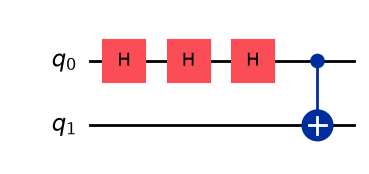

In [2]:
bell = QuantumCircuit(2)
bell.h(0)
bell.h(0)
bell.h(0)
bell.cx(0, 1)
bell.draw("mpl")

:::{admonition} Your turn
:class: tip

Predict which gates the compiler can remove before running a pass.
:::

## Read the imported QC

The compiler first **translates** the Qiskit program to MLIR.
MLIR is a framework for representing and transforming programs.
A **dialect** groups related operations and types:
`qc.h` is the Hadamard operation of the QC dialect, while `func.func` defines a function in the `func` dialect.

In [3]:
qc = QCProgram.from_qiskit(bell)
display(Code(qc.ir, language="mlir"))

module {
  func.func @main() attributes {mqt.entry_point} {
    %alloc = memref.alloc() {mqt.register_name = "q"} : memref<2x!qc.qubit>
    %c0 = arith.constant 0 : index
    %q = memref.load %alloc[%c0] : memref<2x!qc.qubit>
    %c1 = arith.constant 1 : index
    %q_0 = memref.load %alloc[%c1] : memref<2x!qc.qubit>
    qc.h %q : !qc.qubit
    qc.h %q : !qc.qubit
    qc.h %q : !qc.qubit
    qc.ctrl(%q) targets (%q_1 = %q_0) {
      qc.x %q_1 : !qc.qubit
      qc.yield
    } : {!qc.qubit}, {!qc.qubit}
    memref.dealloc %alloc : memref<2x!qc.qubit>
    return
  }
}

:::{admonition} Your turn
:class: tip

Read the output in this order:

- `module` contains the program. Its `func.func @main()` has the
  `mqt.entry_point` attribute identifying the entry point.
- `qc.alloc` allocates a qubit initialized to $|0\rangle$. Each `%...` name
  identifies an **SSA value**: it is defined once, rather than reassigned.
- `!qc.qubit` is the type of a qubit reference. All three `qc.h` operations use
  the same reference. The reference stays the same while the quantum state
  changes. This is **reference semantics**.
- `qc.ctrl` applies the operations in its body under quantum control. The body's
  `%arg...` names are its arguments; here the body applies X to the target
  qubit.
- Braces delimit **regions**, which contain blocks of operations. A block ends
  with a **terminator**: `qc.yield` ends the controlled body, and `return` ends
  the function. `qc.dealloc` releases the allocated qubits.
:::

The printed SSA names are chosen for readability. They are not stable IDs and
can change after a transformation.

## Make quantum data flow explicit with QCO

QC is convenient for import and export: a gate can refer to an existing qubit.
For optimization, it helps to express which operation produces the quantum value
used by the next operation.

:::{admonition} Your turn
:class: tip

Convert QC to QCO to see this change:
:::

In [4]:
qco = qc.to_qco(copy=True)
display(Code(qco.ir, language="mlir"))

module {
  func.func @main() attributes {mqt.entry_point} {
    %c2 = arith.constant 2 : index
    %q = qtensor.alloc(%c2) {mqt.register_name = "q"} : tensor<2x!qco.qubit>
    %c0 = arith.constant 0 : index
    %c1 = arith.constant 1 : index
    %qs, %q_0 = qtensor.extract %q[%c0] : tensor<2x!qco.qubit>
    %q_1 = qco.h %q_0 : !qco.qubit
    %q_2 = qco.h %q_1 : !qco.qubit
    %q_3 = qco.h %q_2 : !qco.qubit
    %qs_4, %q_5 = qtensor.extract %qs[%c1] : tensor<2x!qco.qubit>
    %controls_out, %targets_out = qco.ctrl(%q_3) targets (%q_8 = %q_5) {
      %q_9 = qco.x %q_8 : !qco.qubit
      qco.yield %q_9 : !qco.qubit
    } : ({!qco.qubit}, {!qco.qubit})
    %qs_6 = qtensor.insert %controls_out into %qs_4[%c0] : tensor<2x!qco.qubit>
    %qs_7 = qtensor.insert %targets_out into %qs_6[%c1] : tensor<2x!qco.qubit>
    qtensor.dealloc %qs_7 : tensor<2x!qco.qubit>
    return
  }
}

Each `qco.h` now consumes one qubit value and produces a new one.
Its result feeds the next Hadamard.
QCO uses **value semantics** to make that dependency explicit.

![QC reuses one qubit reference; QCO connects three Hadamards through successive qubit values. Removing two Hadamards reconnects the remaining value flow.](_static/quantum-data-flow.svg)

QCO enforces **linear semantics**: each quantum SSA value has exactly one use.
A gate transfers the value onward; it does not leave an old value available for a second operation.
`qco.ctrl` transfers both the control and target values, even though a controlled-X does not flip its control.
The final `qco.sink` operations consume the values at the end of their lifetimes.

:::{admonition} Your turn
:class: tip

To follow a qubit through the program, trace the operands and results of its operations.
:::

This is also how a rewrite finds the quantum data dependencies.

## Run one optimization and check its meaning

A **pass** inspects or transforms IR.
The `simplify-quantum` pass cancels inverse pairs, combines rotations, and specializes gates.
For example, it cancels adjacent Hadamards on the same qubit.

:::{admonition} Your turn
:class: tip

Predict the gate count before running the next cell.
:::

Gate count before: 4
Gate count after: 2


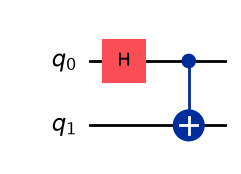

In [5]:
optimized_qco = qco.copy()
optimized_qco.run_pass_pipeline("simplify-quantum")
final_qc = optimized_qco.to_qc(copy=True)

print(f"Gate count before: {qc.num_gates()}")
print(f"Gate count after: {final_qc.num_gates()}")
final_qc.to_qiskit().draw("mpl")

:::{admonition} Your turn
:class: tip

Simulate the optimized program with DDSIM and inspect the state prepared from $|00\rangle$.
:::

In [6]:
state = simulate(optimized_qco)
for index, amplitude in enumerate(state):
    print(f"|{index:02b}>: {amplitude.real:+.3f}{amplitude.imag:+.3f}j")

|00>: +0.707+0.000j
|01>: +0.000+0.000j
|10>: +0.000+0.000j
|11>: +0.707+0.000j


The vector uses basis order $|q_1\,q_0\rangle$, with the higher-index qubit on the
left.
Only $|00\rangle$ and $|11\rangle$ have nonzero amplitudes, each $1/\sqrt{2}$.
Their measurement probabilities are $1/2$.

## Locate this pass in the full compiler

We selected one pass to explain its effect. Ordinary `compile_program` calls
coordinate frontend preparation, conversion, optimization, and output lowering.

![OpenQASM is imported into QC, converted to QCO, optimized, and converted back to QC for export. Target compilation adds placement, routing, and native synthesis before emission. Submission is a separate step.](_static/compiler-pipeline.svg)

Inspection checkpoints in the compiler. A target's capabilities and the chosen
output format also determine the required compilation steps.

The following calls expose four checkpoints. The first two do not run the
configured QCO optimization pipeline, though import and conversion can perform
their own preparation and cleanup.

In [7]:
qc = compile_program(bell, output=OutputFormat.QC_IMPORT)
qco = compile_program(bell, output=OutputFormat.QCO)
optimized_qco = compile_program(bell, output=OutputFormat.QCO_OPTIMIZED)
final_qc = compile_program(bell, output=OutputFormat.QC)
print(f"Imported QC gates: {qc.num_gates()}")
print(f"Final QC gates: {final_qc.num_gates()}")

Imported QC gates: 4
Final QC gates: 2


:::{admonition} Your turn
:class: tip

Inspect the optimized QCO and final QC below.
:::

The conversion back to reference
semantics preserves the optimized program.

In [8]:
display(Code(optimized_qco.ir, language="mlir"))
display(Code(final_qc.ir, language="mlir"))

module {
  func.func @main() attributes {mqt.entry_point} {
    %c1 = arith.constant 1 : index
    %c0 = arith.constant 0 : index
    %c2 = arith.constant 2 : index
    %q = qtensor.alloc(%c2) {mqt.register_name = "q"} : tensor<2x!qco.qubit>
    %qs, %q_0 = qtensor.extract %q[%c0] : tensor<2x!qco.qubit>
    %q_1 = qco.h %q_0 : !qco.qubit
    %qs_2, %q_3 = qtensor.extract %qs[%c1] : tensor<2x!qco.qubit>
    %controls_out, %targets_out = qco.ctrl(%q_1) targets (%q_6 = %q_3) {
      %q_7 = qco.x %q_6 : !qco.qubit
      qco.yield %q_7 : !qco.qubit
    } : ({!qco.qubit}, {!qco.qubit})
    %qs_4 = qtensor.insert %controls_out into %qs_2[%c0] : tensor<2x!qco.qubit>
    %qs_5 = qtensor.insert %targets_out into %qs_4[%c1] : tensor<2x!qco.qubit>
    qtensor.dealloc %qs_5 : tensor<2x!qco.qubit>
    return
  }
}

module {
  func.func @main() attributes {mqt.entry_point} {
    %c1 = arith.constant 1 : index
    %c0 = arith.constant 0 : index
    %c2 = arith.constant 2 : index
    %alloc = memref.alloc() {mqt.register_name = "q"} : memref<2x!qc.qubit>
    %q = memref.load %alloc[%c0] : memref<2x!qc.qubit>
    qc.h %q : !qc.qubit
    %q_0 = memref.load %alloc[%c1] : memref<2x!qc.qubit>
    qc.ctrl(%q) targets (%q_1 = %q_0) {
      qc.x %q_1 : !qc.qubit
      qc.yield
    } : {!qc.qubit}, {!qc.qubit}
    memref.dealloc %alloc : memref<2x!qc.qubit>
    return
  }
}

## Checkpoint: Move to hardware compilation

You have inspected QC/QCO, removed two gates, and simulated the output state.

:::{admonition} Your turn
:class: tip

Open **hardware_compilation.ipynb** for the next 20 minutes.
:::

Everything below
is an optional extension.

Use `qco_pipeline="canonicalize"` to replace the default QCO optimization
pipeline with classical and structural cleanup in a target-independent
compilation. The compiler still runs its preparation and output stages. See the
[compiler guide](https://mqt.readthedocs.io/projects/core/en/stable/mlir/mqt_compiler_collection.html#run-passes-explicitly) for
composing passes; the tutorial's target compilation uses the coordinated target
pipeline.

## Experiment: Which Hadamards cancel?

:::{admonition} Your turn
:class: tip

Predict the effect of zero through four consecutive Hadamards.
Run the cell to check each variant and inspect its remaining gate count.
:::

In [9]:
for hadamards in range(5):
    circuit = QuantumCircuit(2)
    for _ in range(hadamards):
        circuit.h(0)
    circuit.cx(0, 1)
    qco = QCProgram.from_qiskit(circuit).to_qco()
    optimized_qco = qco.copy()
    optimized_qco.run_pass_pipeline("simplify-quantum")
    np.testing.assert_allclose(
        build_functionality(optimized_qco),
        build_functionality(qco),
        rtol=0,
        atol=1e-12,
    )
    gates = optimized_qco.num_gates()
    assert gates == 1 + hadamards % 2
    print(f"{hadamards} Hadamards → {gates} total gates")

0 Hadamards → 1 total gates
1 Hadamards → 2 total gates
2 Hadamards → 1 total gates
3 Hadamards → 2 total gates
4 Hadamards → 1 total gates


:::{dropdown} Explain the result

An even number of Hadamards acts as the identity; an odd number acts as one
Hadamard. The controlled-X remains in both cases. Although it leaves
$|00\rangle$ unchanged, it acts on other possible inputs, so removing it would
change the program's full unitary.
:::

:::{admonition} Your turn
:class: tip

Now replace the three Hadamards with **H, Z, H**. Can you still cancel the two
Hadamards across Z? Predict the final state before running:
:::

In [10]:
circuit = QuantumCircuit(2)
circuit.h(0)
circuit.z(0)
circuit.h(0)
circuit.cx(0, 1)
qco = QCProgram.from_qiskit(circuit).to_qco()
optimized_qco = qco.copy()
optimized_qco.run_pass_pipeline("simplify-quantum")
np.testing.assert_allclose(
    build_functionality(optimized_qco),
    build_functionality(qco),
    rtol=0,
    atol=1e-12,
)
np.testing.assert_allclose(simulate(optimized_qco), [0, 0, 0, 1], rtol=0, atol=1e-12)
print(simulate(optimized_qco))

[0.+0.j 0.+0.j 0.+0.j 1.+0.j]


:::{dropdown} Explain the result

$HZH = X$, not $Z$. Starting from $|00\rangle$, X flips qubit 0, and the
controlled-X then flips qubit 1, producing $|11\rangle$. Removing the Hadamards
across Z would be incorrect. A different rewrite may use the complete identity
$HZH = X$; this is not cancellation of adjacent inverse gates.
:::

Continue with [Follow registers and control flow](https://mqt.readthedocs.io/projects/core/en/stable/tutorials/control_flow.html) to see how quantum values move through
registers and control flow. For operation definitions and implementation
guidance, use the [QC](https://mqt.readthedocs.io/projects/core/en/stable/mlir/QC.html), [QCO](https://mqt.readthedocs.io/projects/core/en/stable/mlir/QCO.html), and
[MLIR development policy](https://mqt.readthedocs.io/projects/core/en/stable/development.html#mlir) references.